In [1]:
# Imports

import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.dataset as ds

In [2]:
# Load

dataset = ds.dataset(
    "data/weather.parquet",
    format="parquet"
)

table = dataset.to_table(
    columns=["time", "temperature_2m"]
)

df = table.to_pandas()
df["time"] = df["time"].dt.tz_convert("America/Edmonton")

df.head()

,time,temperature_2m
0,2000-01-01 00:00:00-07:00,-4.5
1,2000-01-01 01:00:00-07:00,-4.6
2,2000-01-01 02:00:00-07:00,-4.7
3,2000-01-01 03:00:00-07:00,-6.9
4,2000-01-01 04:00:00-07:00,-7.2


In [3]:
# Inspect

# Structure
print(df["time"].min(), "to", df["time"].max())
print("Shape:", df.shape, "\n")
print("Dtypes:")
print(df.dtypes, "\n")

# Missingness
print("Any Nulls:", df.isna().any().any(), "\n")

# Duplicates
print("Duplicate Rows:", df.duplicated().any())
print("Duplicate Times:", df["time"].duplicated().any(), "\n")

# Temporal Sanity
print("Non-Monotonic Times:", not df["time"].is_monotonic_increasing)
print("Unexpected Time Deltas:", df["time"].diff().dropna().ne(pd.Timedelta(hours = 1)).any())

2000-01-01 00:00:00-07:00 to 2026-09-30 23:00:00-06:00
Shape: (234479, 2) 

Dtypes:
time              datetime64[ms, America/Edmonton]
temperature_2m                             float64
dtype: object 

Any Nulls: False 

Duplicate Rows: False
Duplicate Times: False 

Non-Monotonic Times: False
Unexpected Time Deltas: False


In [4]:
df[["temperature_2m"]].describe().T

,count,mean,std,min,25%,50%,75%,max
temperature_2m,234479.0,4.709839,11.51252,-42.9,-2.2,5.1,12.7,38.2


In [5]:
# Clean
# No clean required after inspect.

In [6]:
# Transform

filter_df = df.loc[(df["time"].dt.year.eq(2025)) & 
                   (df["time"].dt.month.isin([1, 7]))].copy()

filter_df["date"] = filter_df["time"].dt.normalize()

output_df = (filter_df.groupby(["date"], as_index = False)
                          .agg(avg_temp = ("temperature_2m", "mean"))
                          .assign(month = lambda x: x["date"].dt.month,
                                  date = lambda x: x["date"].dt.date)
                          .loc[:, ["date", "month", "avg_temp"]]
)

output_df

,date,month,avg_temp
0,2025-01-01,1,-11.770833
1,2025-01-02,1,-14.387500
2,2025-01-03,1,-14.979167
3,2025-01-04,1,-14.137500
4,2025-01-05,1,-15.129167
...,...,...,...
57,2025-07-27,7,13.150000
58,2025-07-28,7,14.329167
59,2025-07-29,7,16.912500
60,2025-07-30,7,18.666667


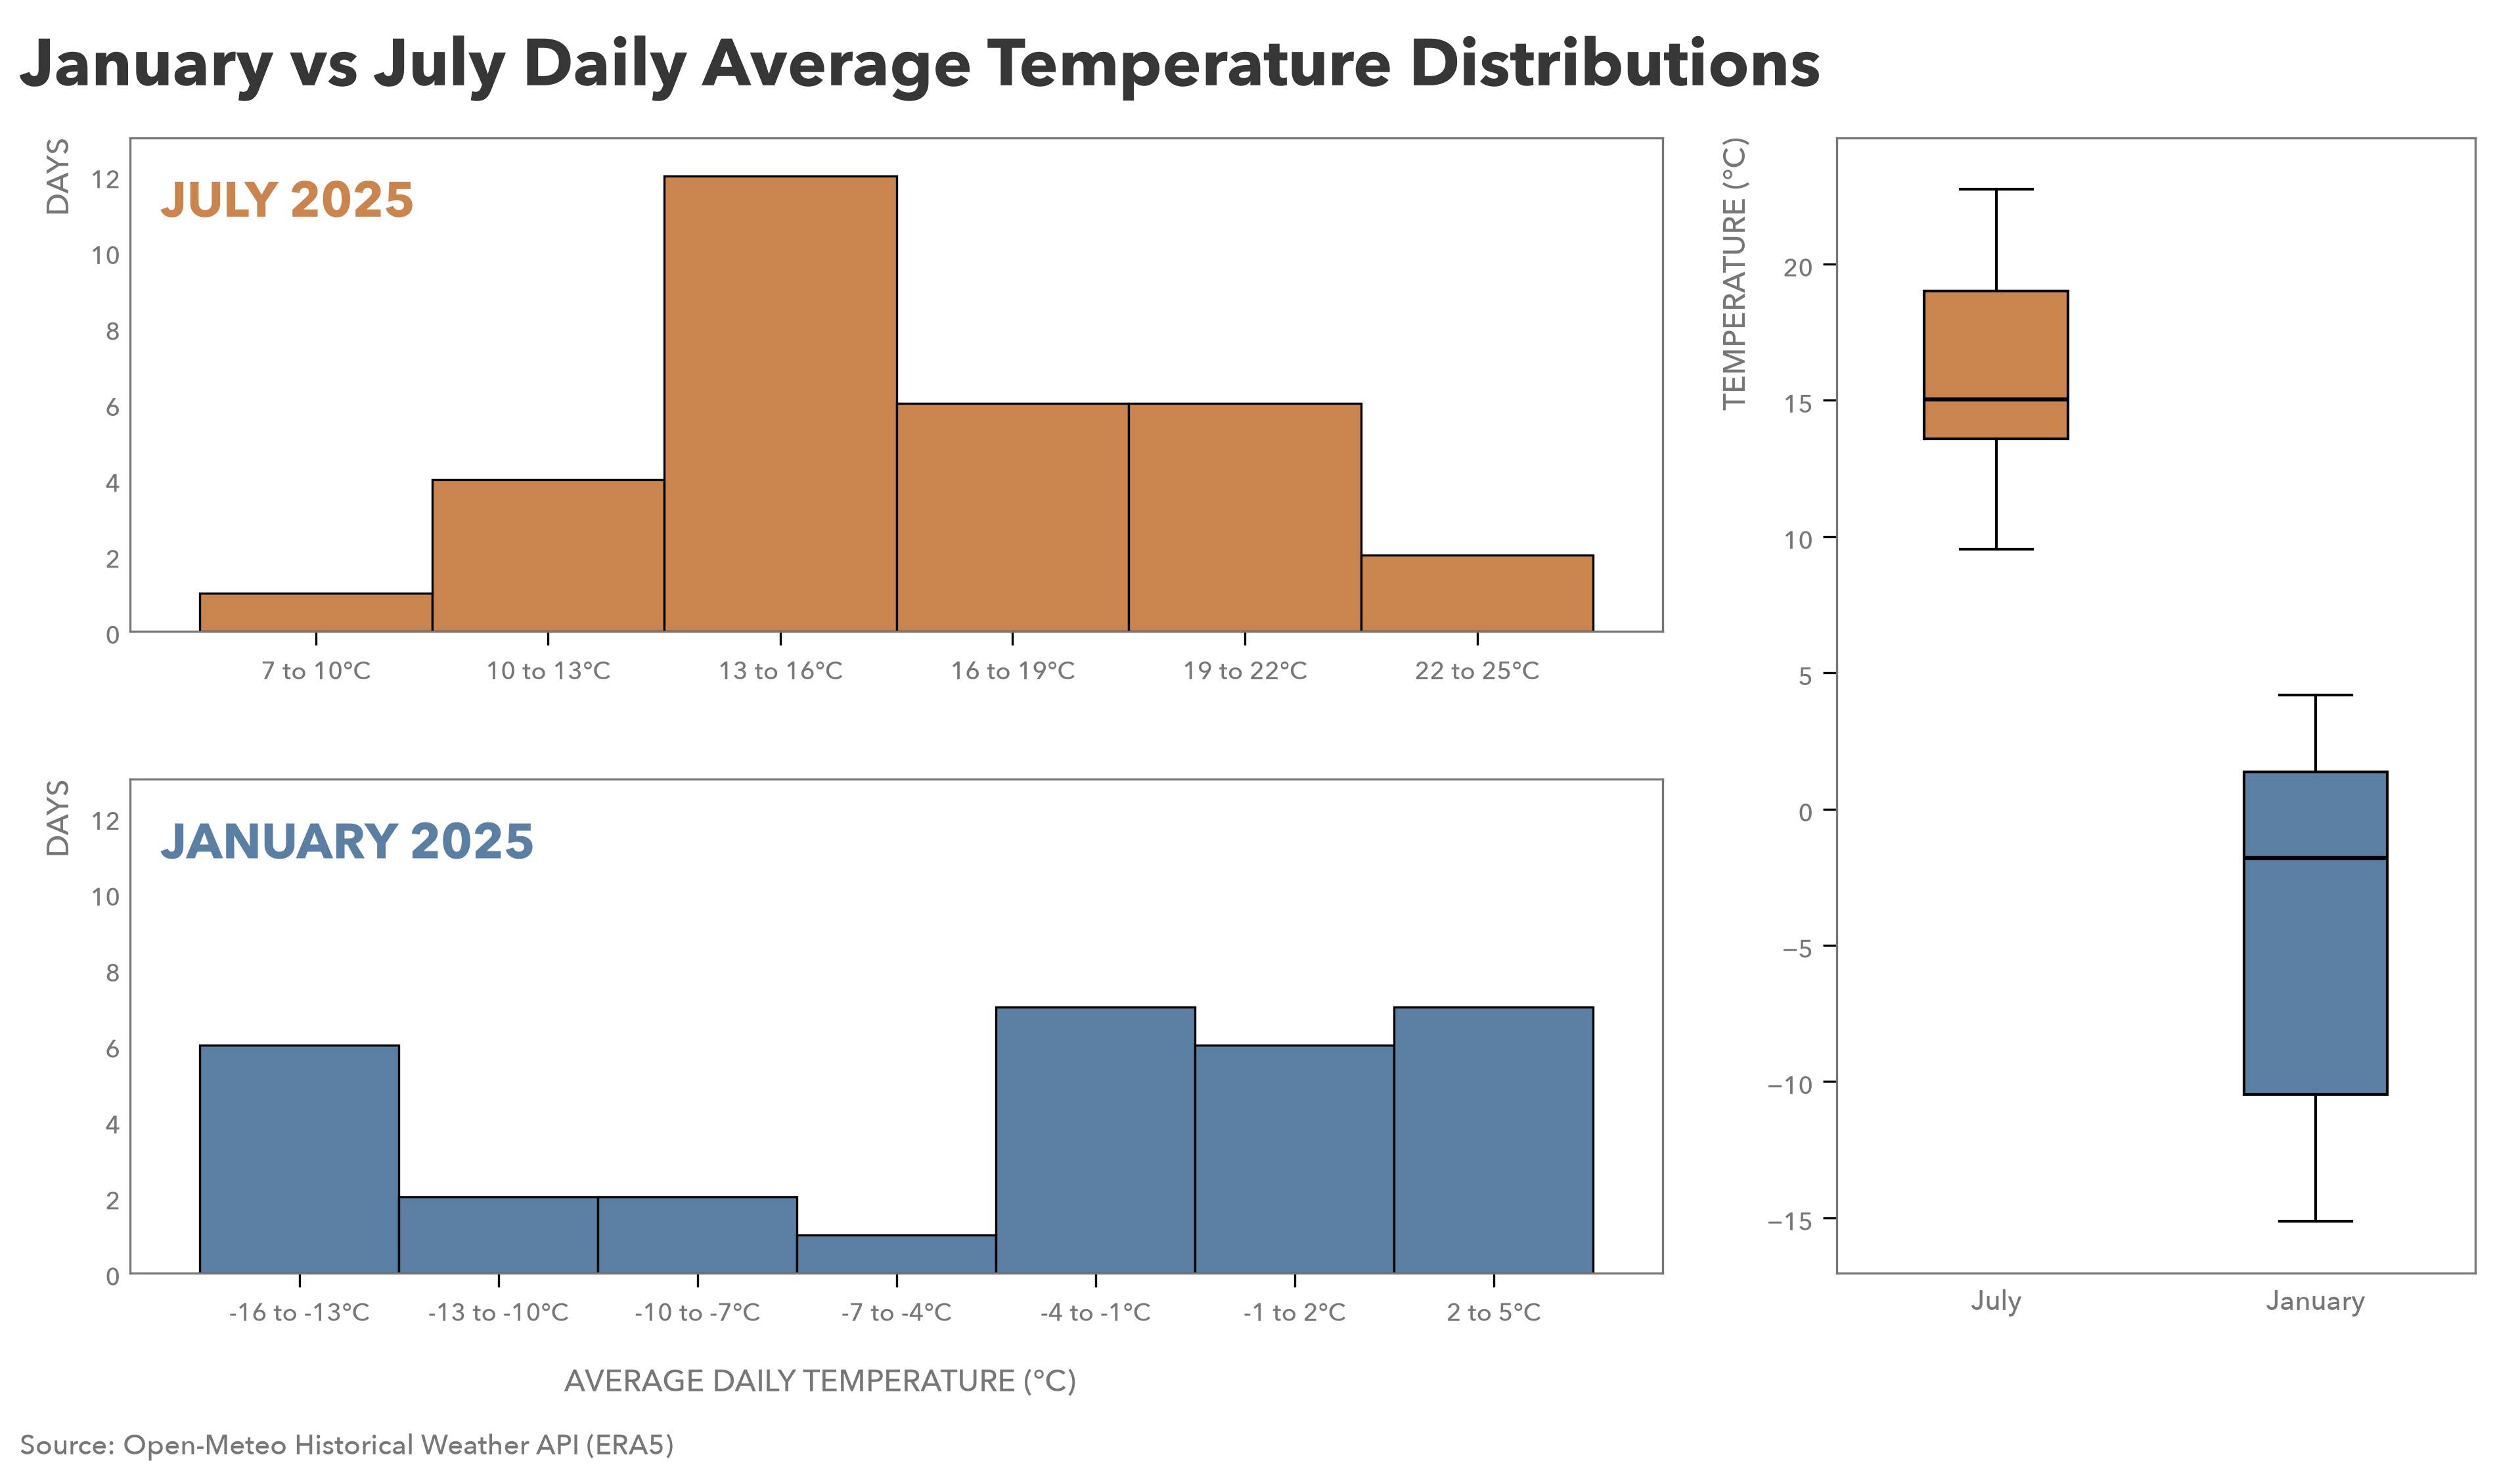

In [7]:
# Visualize

# Figure

plt.rcParams["font.family"] = "Avenir Next"
plt.rcParams["font.weight"] = 500

fig = plt.figure(figsize = (14, 8), dpi = 300)

gs = fig.add_gridspec(
    2, 2,
    width_ratios = [2.4, 1],
    height_ratios = [1, 1],
    wspace = 0.16,
    hspace = 0.30
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[:, 1])

fig.subplots_adjust(
    left = 0.10,
    right = 0.95,
    top = 0.86,
    bottom = 0.14
)

STRUCTURE = "#777777"
GRID = "#B3B3B3"
JANUARY = "#5B7FA3"
JULY = "#C9854D"
BLACK = "k"
TITLE = "#363636"

# Plot

# plot data
january = output_df.loc[output_df["month"].eq(1), "avg_temp"]
july = output_df.loc[output_df["month"].eq(7), "avg_temp"]

# histogram bins
july_bins = [7, 10, 13, 16, 19, 22, 25]
jan_bins = [-16, -13, -10, -7, -4, -1, 2, 5]

# histograms
july_counts, july_edges, _ = ax1.hist(july, bins = july_bins, color = JULY, edgecolor = BLACK, linewidth = 0.8)
jan_counts, jan_edges, _ = ax2.hist(january, bins = jan_bins, color = JANUARY, edgecolor = BLACK, linewidth = 0.8)

# boxplots
boxplots = ax3.boxplot(
    [january, july],
    orientation = "vertical",
    positions = [2, 1],
    widths = 0.45,
    patch_artist = True,
    tick_labels = ["January", "July"]
)

boxplots["boxes"][0].set(facecolor = JANUARY, edgecolor = BLACK, linewidth = 1)
boxplots["boxes"][1].set(facecolor = JULY, edgecolor = BLACK, linewidth = 1)

for median in boxplots["medians"]:
    median.set(color = BLACK, linewidth = 1.5)

# Emphasis

# Scale & Axes

hist_max = max(july_counts.max(), jan_counts.max())
hist_ylim = int(hist_max) + 1

ax1.set_ylim(0, hist_ylim)
ax2.set_ylim(0, hist_ylim)

ax1.set_ylabel("DAYS", loc = "top", fontsize = 11, fontweight = 500, color = STRUCTURE)
ax2.set_ylabel("DAYS", loc = "top", fontsize = 11, fontweight = 500, color = STRUCTURE)

fig.text(0.35, 0.065, "AVERAGE DAILY TEMPERATURE (°C)", ha = "center", fontsize = 11, fontweight = 500, color = STRUCTURE)

ax3.set_ylabel("TEMPERATURE (°C)", loc = "top", fontsize = 11, fontweight = 500, color = STRUCTURE)

# histogram identification
ax1.text(0.02, 0.94, "JULY 2025", transform = ax1.transAxes, ha = "left", va = "top", fontsize = 18, fontweight = 700, color = JULY)
ax2.text(0.02, 0.94, "JANUARY 2025", transform = ax2.transAxes, ha = "left", va = "top", fontsize = 18, fontweight = 700, color = JANUARY)

# Ticks

# histogram y ticks
even_ticks = range(0, hist_ylim + 1, 2)

ax1.set_yticks(even_ticks)
ax2.set_yticks(even_ticks)

# histogram bin labels
july_midpoints = (july_edges[:-1] + july_edges[1:]) / 2
jan_midpoints = (jan_edges[:-1] + jan_edges[1:]) / 2

july_labels = [f"{left:g} to {right:g}°C" for left, right in zip(july_edges[:-1], july_edges[1:])]
jan_labels = [f"{left:g} to {right:g}°C" for left, right in zip(jan_edges[:-1], jan_edges[1:])]

ax1.set_xticks(july_midpoints, labels = july_labels)
ax2.set_xticks(jan_midpoints, labels = jan_labels)

ax1.tick_params(axis = "x", labelsize = 9, length = 5, labelcolor = STRUCTURE)
ax2.tick_params(axis = "x", labelsize = 9, length = 5, labelcolor = STRUCTURE)

ax1.tick_params(axis = "y", labelsize = 9, length = 0, labelcolor = STRUCTURE)
ax2.tick_params(axis = "y", labelsize = 9, length = 0, labelcolor = STRUCTURE)

ax3.tick_params(axis = "x", labelsize = 10, length = 0, labelcolor = STRUCTURE)
ax3.tick_params(axis = "y", labelsize = 9, length = 5, labelcolor = STRUCTURE)

# Styling

for ax in [ax1, ax2, ax3]:
    for spine in ax.spines.values():
        spine.set_color(STRUCTURE)
        spine.set_linewidth(0.8)

# Composition

fig.suptitle(
    "January vs July Daily Average Temperature Distributions",
    x = 0.06,
    y = 0.935,
    ha = "left",
    va = "top",
    fontsize = 24,
    fontweight = 700,
    color = TITLE
)

fig.text(0.06, 0.025, "Source: Open-Meteo Historical Weather API (ERA5)", fontsize = 10, color = STRUCTURE)

# Outputs

fig.savefig("outputs/january-vs-july-avg-temp-distribution-2025.svg", bbox_inches = "tight", pad_inches = 0.1)
plt.show()